# Practical 4 - Data Visualisation with Matplotlib
Dataset: Breast Cancer Wisconsin (569 tumour samples, measurements from cell-nucleus images)

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

HERE = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
def find_data(name):
    """Look for the CSV in the usual places; in Colab, ask for an upload if it is missing."""
    folders = (HERE.parent / "Datasets", HERE / "Datasets", HERE, Path.cwd(),
               Path("/content"), Path("/content/Datasets"), Path("/content/drive/MyDrive"))
    for folder in folders:
        if (folder / name).exists():
            return folder
    try:
        from google.colab import files
        print(f"{name} not found - please choose it in the upload dialog (it is in the Datasets folder).")
        files.upload()
        return Path.cwd()
    except ImportError:
        raise FileNotFoundError(f"Could not find {name}. Put it in a 'Datasets' folder next to this script.")

DATA = find_data("breast_cancer.csv")
FIG = HERE / "figures"
FIG.mkdir(exist_ok=True)

tumours = pd.read_csv(DATA / "breast_cancer.csv")
focus = ["mean radius", "mean texture", "mean area", "mean concavity", "diagnosis"]
print("Full table shape :", tumours.shape)
print(tumours[focus].head().to_string())

Full table shape : (569, 31)
   mean radius  mean texture  mean area  mean concavity  diagnosis
0        17.99         10.38     1001.0          0.3001  malignant
1        20.57         17.77     1326.0          0.0869  malignant
2        19.69         21.25     1203.0          0.1974  malignant
3        11.42         20.38      386.1          0.2414  malignant
4        20.29         14.34     1297.0          0.1980  malignant


## 1. Checking for duplicate records

In [2]:
exact = tumours.duplicated().sum()
by_profile = tumours.duplicated(subset=["mean radius", "mean texture", "mean area"]).sum()
cleaned = tumours.drop_duplicates(subset=["mean radius", "mean texture", "mean area"])
print("Exact duplicate rows            :", int(exact))
print("Duplicates on radius/texture/area:", int(by_profile))
print("Rows before / after cleaning    :", len(tumours), "/", len(cleaned))

Exact duplicate rows            : 0
Duplicates on radius/texture/area: 0
Rows before / after cleaning    : 569 / 569


## 2. Summary statistics of the selected measurements

In [3]:
print(cleaned[focus[:-1]].describe().round(3).to_string())
print("\nSamples per diagnosis:")
print(cleaned["diagnosis"].value_counts().to_string())

       mean radius  mean texture  mean area  mean concavity
count      569.000       569.000    569.000         569.000
mean        14.127        19.290    654.889           0.089
std          3.524         4.301    351.914           0.080
min          6.981         9.710    143.500           0.000
25%         11.700        16.170    420.300           0.030
50%         13.370        18.840    551.100           0.062
75%         15.780        21.800    782.700           0.131
max         28.110        39.280   2501.000           0.427

Samples per diagnosis:
diagnosis
benign       357
malignant    212


## 3. Average tumour area by diagnosis (bar chart)

             mean     std
diagnosis                
benign     462.79  134.29
malignant  978.38  367.94


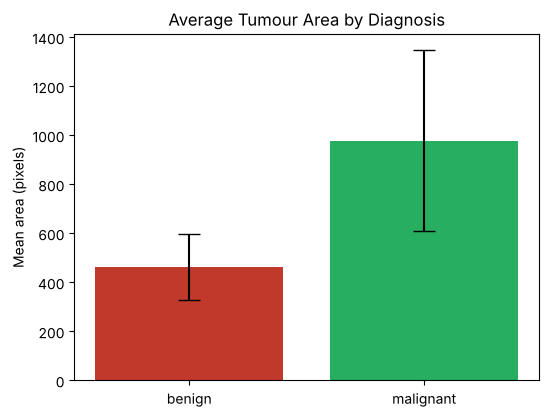

In [4]:
area_by_dx = cleaned.groupby("diagnosis")["mean area"].agg(["mean", "std"])
print(area_by_dx.round(2).to_string())

plt.figure(figsize=(6, 4.5))
plt.bar(area_by_dx.index, area_by_dx["mean"], yerr=area_by_dx["std"], capsize=8,
        color=["#c0392b", "#27ae60"])
plt.title("Average Tumour Area by Diagnosis")
plt.ylabel("Mean area (pixels)")
plt.savefig(FIG / "bar_area_by_diagnosis.png", dpi=120, bbox_inches="tight")
plt.show()

## 4. Radius against concavity (all samples)

Correlation between radius and concavity: 0.677


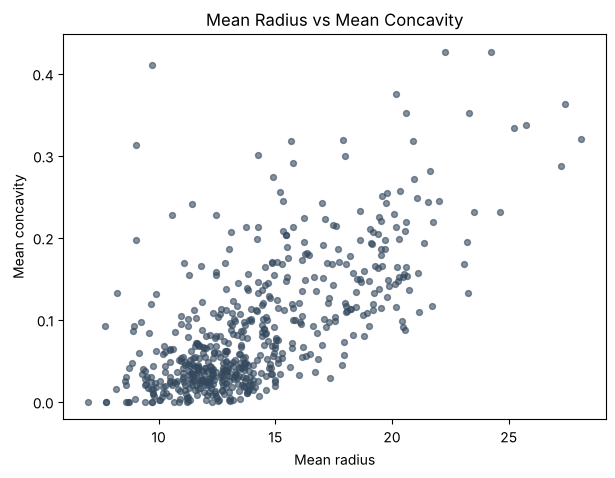

In [5]:
plt.figure(figsize=(7, 5))
plt.scatter(cleaned["mean radius"], cleaned["mean concavity"], s=18, alpha=0.6, color="#34495e")
plt.title("Mean Radius vs Mean Concavity")
plt.xlabel("Mean radius")
plt.ylabel("Mean concavity")
plt.savefig(FIG / "scatter_radius_concavity.png", dpi=120, bbox_inches="tight")
plt.show()
r = cleaned["mean radius"].corr(cleaned["mean concavity"])
print(f"Correlation between radius and concavity: {r:.3f}")

## 5. Same scatter, coloured by diagnosis

benign     mean radius = 12.15, mean concavity = 0.046
malignant  mean radius = 17.46, mean concavity = 0.161


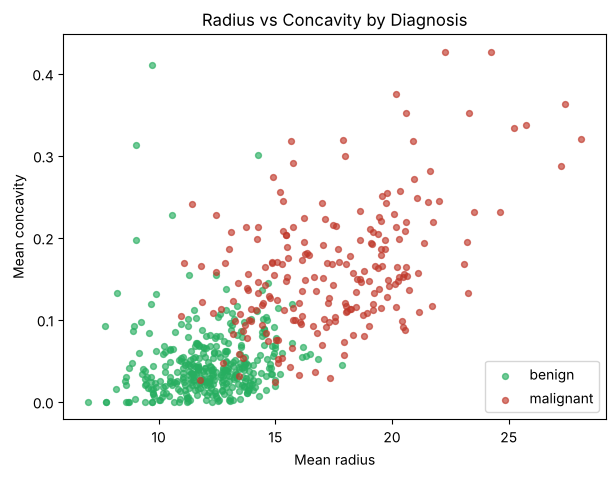

In [6]:
palette = {"malignant": "#c0392b", "benign": "#27ae60"}
plt.figure(figsize=(7, 5))
for label, part in cleaned.groupby("diagnosis"):
    plt.scatter(part["mean radius"], part["mean concavity"], s=18, alpha=0.65,
                color=palette[label], label=label)
plt.title("Radius vs Concavity by Diagnosis")
plt.xlabel("Mean radius")
plt.ylabel("Mean concavity")
plt.legend()
plt.savefig(FIG / "scatter_by_diagnosis.png", dpi=120, bbox_inches="tight")
plt.show()

for label, part in cleaned.groupby("diagnosis"):
    print(f"{label:<10} mean radius = {part['mean radius'].mean():.2f}, mean concavity = {part['mean concavity'].mean():.3f}")

## 6. Four groups: diagnosis x texture level

diagnosis  texture_level
benign     rough            119
           smooth           238
malignant  rough            166
           smooth            46


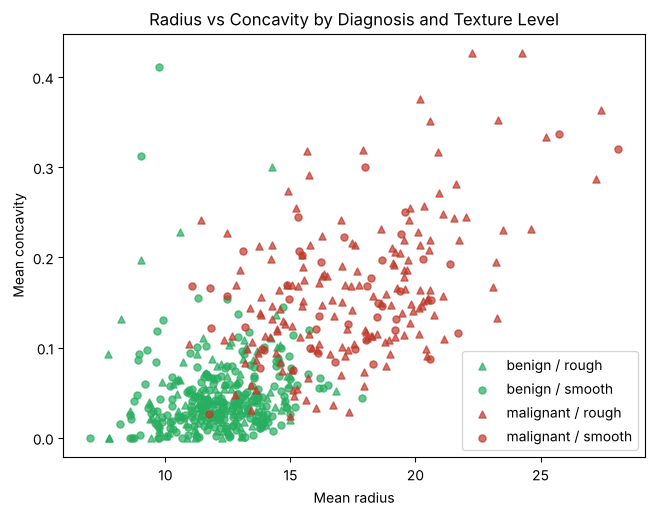

In [7]:
texture_cut = cleaned["mean texture"].median()
grouped = cleaned.assign(texture_level=np.where(cleaned["mean texture"] >= texture_cut, "rough", "smooth"))

markers = {"smooth": "o", "rough": "^"}
plt.figure(figsize=(7.5, 5.5))
for (dx, tex), part in grouped.groupby(["diagnosis", "texture_level"]):
    plt.scatter(part["mean radius"], part["mean concavity"], s=26, alpha=0.7,
                color=palette[dx], marker=markers[tex], label=f"{dx} / {tex}")
plt.title("Radius vs Concavity by Diagnosis and Texture Level")
plt.xlabel("Mean radius")
plt.ylabel("Mean concavity")
plt.legend()
plt.savefig(FIG / "scatter_four_groups.png", dpi=120, bbox_inches="tight")
plt.show()

print(grouped.groupby(["diagnosis", "texture_level"]).size().rename("samples").to_string())